# DBSCAN — Density-Based Clustering

## 1. Definition and intuition
DBSCAN groups points connected by dense neighborhoods. It distinguishes core points (many neighbors), border points (near a core but not themselves dense), and noise points. Unlike K-means, it does not require specifying the number of clusters and can find irregular shapes.

## 2. Definitions
A point is a core point when its \(\varepsilon\)-neighborhood contains at least `min_samples` observations (conventionally including the point itself). A core point is density-reachable from another core point via a chain of neighboring core points. Border points attach to a cluster but do not expand it. Points not assigned to any cluster are labeled noise (-1).

## 3. Why it works and assumptions
DBSCAN is a graph reachability procedure on local density neighborhoods; the labels follow from connected components of the core-point neighborhood graph, with adjacent border points attached. It is not optimizing a centroid objective, and border-point membership can be ambiguous when near multiple clusters.

It assumes a meaningful distance metric and density scale. It struggles when clusters have very different densities or when distance is uninformative in high dimensions.

## 4. Dataset: non-convex moons plus noise

DBSCAN can discover crescent-shaped clusters that centroid-based K-means cannot represent naturally.

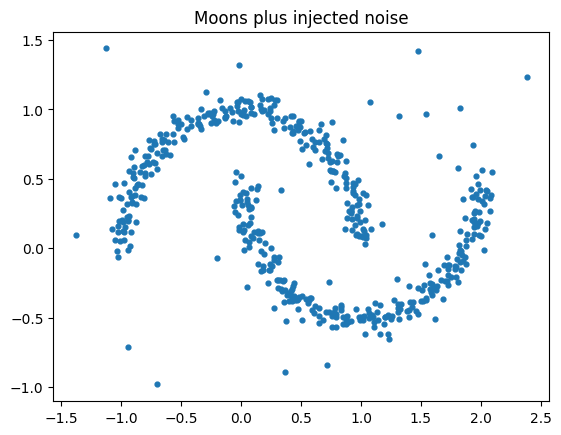

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.cluster import DBSCAN as SkDBSCAN, KMeans
from sklearn.metrics import adjusted_rand_score
from sklearn.neighbors import NearestNeighbors

SEED = 42
X, y_true = make_moons(n_samples=500, noise=0.055, random_state=SEED)
rng = np.random.default_rng(SEED)
noise = rng.uniform(low=[-1.5, -1.0], high=[2.5, 1.5], size=(35, 2))
X_noisy = np.vstack([X, noise])
y_extended = np.concatenate([y_true, np.full(len(noise), -1)])
plt.scatter(X_noisy[:, 0], X_noisy[:, 1], s=12)
plt.title("Moons plus injected noise")
plt.show()


## 5. DBSCAN from scratch

This pedagogical implementation uses brute-force distances, suitable for small datasets only. It follows the classic expansion procedure and treats a point as a neighbor of itself.

In [2]:
def dbscan_scratch(X, eps, min_samples):
    X = np.asarray(X, dtype=float)
    if X.ndim != 2 or len(X) == 0 or not np.isfinite(X).all():
        raise ValueError("X must be a non-empty finite 2D array")
    if eps <= 0 or min_samples < 1:
        raise ValueError("eps and min_samples must be positive")
    n = len(X)
    d2 = np.sum((X[:, None, :] - X[None, :, :])**2, axis=2)
    neighborhoods = [np.flatnonzero(d2[i] <= eps*eps).tolist() for i in range(n)]
    labels = np.full(n, -99, dtype=int)  # unvisited
    cluster_id = 0
    for i in range(n):
        if labels[i] != -99:
            continue
        neighbors = neighborhoods[i]
        if len(neighbors) < min_samples:
            labels[i] = -1
            continue
        labels[i] = cluster_id
        seeds = list(neighbors)
        seed_set = set(seeds)
        cursor = 0
        while cursor < len(seeds):
            q = seeds[cursor]
            cursor += 1
            if labels[q] == -1:
                labels[q] = cluster_id
            if labels[q] != -99:
                continue
            labels[q] = cluster_id
            q_neighbors = neighborhoods[q]
            if len(q_neighbors) >= min_samples:
                for r in q_neighbors:
                    if r not in seed_set:
                        seeds.append(r)
                        seed_set.add(r)
        cluster_id += 1
    return labels

labels_scratch = dbscan_scratch(X_noisy, eps=0.16, min_samples=6)
print("Scratch clusters:", sorted(set(labels_scratch) - {-1}), "noise count:", int(np.sum(labels_scratch == -1)))


Scratch clusters: [np.int64(0), np.int64(1)] noise count: 20


## 6. Compare with scikit-learn

DBSCAN cluster IDs are arbitrary; ARI is invariant to permutation. Because border/noise assignments can differ at the margins, evaluate the structure and noise rate, not exact label equality.

Scratch DBSCAN ARI: 0.942
sklearn DBSCAN ARI: 0.942
K-means ARI: 0.2129


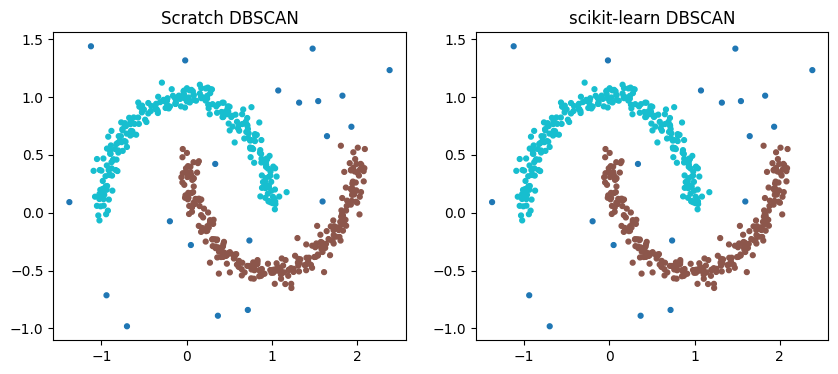

In [3]:
db = SkDBSCAN(eps=0.16, min_samples=6).fit(X_noisy)
km = KMeans(n_clusters=2, n_init=10, random_state=SEED).fit(X_noisy)
print("Scratch DBSCAN ARI:", round(adjusted_rand_score(y_extended, labels_scratch), 4))
print("sklearn DBSCAN ARI:", round(adjusted_rand_score(y_extended, db.labels_), 4))
print("K-means ARI:", round(adjusted_rand_score(y_extended, km.labels_), 4))
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].scatter(X_noisy[:,0], X_noisy[:,1], c=labels_scratch, s=12, cmap="tab10")
axes[0].set_title("Scratch DBSCAN")
axes[1].scatter(X_noisy[:,0], X_noisy[:,1], c=db.labels_, s=12, cmap="tab10")
axes[1].set_title("scikit-learn DBSCAN")
plt.show()


## 7. Hyperparameters and complexity

- `eps`: neighborhood radius; too small labels many points noise, too large merges clusters.
- `min_samples`: higher values require denser core neighborhoods and generally suppress small clusters.
- `metric`: distance geometry must match feature meaning.
- Choose scales using domain knowledge and k-distance plots; scale features only when justified.
- Brute force stores all pairwise distances: \(O(n^2d)\) time and \(O(n^2)\) memory. Spatial indexes may accelerate low-dimensional cases, but can degrade in high dimensions.
- For millions of points, consider sparse radius-neighbor graphs, spatial indexing, approximate neighbors or HDBSCAN/OPTICS depending on constraints.
- DBSCAN's fit labels are transductive; predicting labels for unseen points is not part of the basic estimator API.

## 8. GPU and synthesis

A pairwise-distance GPU implementation is possible but an \(n\times n\) distance matrix becomes prohibitive quickly. Chunked neighborhood search or GPU radius graphs are more realistic than blindly allocating the full matrix. Use the library implementation for scale.

In [4]:
assert labels_scratch.shape == (len(X_noisy),)
assert np.issubdtype(labels_scratch.dtype, np.integer)
assert -1 in labels_scratch or len(set(labels_scratch)) >= 1
try:
    dbscan_scratch(np.array([1,2,3]), eps=0.2, min_samples=3)
except ValueError:
    pass
else:
    raise AssertionError("Expected invalid X shape to raise")
print("All DBSCAN checks passed.")


All DBSCAN checks passed.
